# HW05 - Common-gate LNA

Select **ECE6420 (Local)** as the notebook kernel, connect GlobalProtect, and choose **Run All**. This local kernel sends computation to `gt-ece`, receives numerical data, and renders the results and FFT stem plots locally.

| Notebook | Analysis | Dependencies |
|---|---|---|
| [01_b](01_b.ipynb) | Output resonance | Original part-(a) W1 |
| [02_c](02_c.ipynb) | Coupled W1/L1 tuning and Rin | b |
| [03_d](03_d.ipynb) | Stage-1 gain / IIP3 | c |
| [04_e](04_e.ipynb) | Stage-2 resonance / gain / IIP3 | Independent |
| [05_f](05_f.ipynb) | Physical cascade and amplitude sweep | c,d,e |
| [06_g](06_g.ipynb) | Input impedance before / after cascade | c,e,f |

The original starting W1 = 6.93 um differs from the solution's 105.94 um. The solution also mixes voltage/power conventions. The comparison table is a reference, not an automatic correctness test.

The original Fourier projection can omit a boundary sample. Legacy IIP3 and the exact coherent-window check are shown separately; the part-(e) difference is significant. A single-point estimate still needs cubic-scaling validation.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Run and plot the complete analysis
Run this cell, or choose Run All. It computes b-g on the school server, receives numerical data, and immediately renders the summary and FFT stem plots below using this local kernel.

In [2]:
if EXECUTION_MODE == "remote":
    run_remote_parts("bcdefg")
    show_summary()
    for part in "def":
        spectrum(part, require_part(load_meta(), part)["outputs"])

## Local results and plots

| Part | Status | Completed UTC |
|---|---|---|
| b | complete | 2026-10-25T20:21:43.999165+00:00 |
| c | complete | 2026-10-25T20:29:11.946628+00:00 |
| d | complete | 2026-10-25T20:29:36.548700+00:00 |
| e | complete | 2026-10-25T20:30:24.593179+00:00 |
| f | complete | 2026-10-25T20:31:17.239353+00:00 |
| g | complete | 2026-10-25T20:33:10.168400+00:00 |

| Metric | This run | Solution reference | PDF page |
|---|---|---|---|
| (a) W1 (um), starting value | 6.93 | 105.94 | 1 |
| (b) L1 (nH) | 7.9239 | 3.15 | 3 |
| (c) retuned L1 (nH) | 5.7222 | 3.26 | 5 |
| (d) gain (dB), source reference | 17.267 | 9.98 | 8 |
| (d) IIP3 (printed dBV) | -10.492 | -14.25 | 8 |
| (e) L2 (nH) | 3.8306 | 3.9 | 9 |
| (e) gain (dB) | 8.6037 | 6.86 | 10 |
| (f) total gain (dB) | 27.783 | 18.74 | 12 |
| (f) IIP3 (printed dBV) | -16.655 | -18 | 12 |
| (g) Rin after cascade (ohm) | 22.258 | 39.41 | 13 |

**These are comparison references, not pass/fail tolerances.** The starting W1 and source amplitudes differ. The solution mixes voltage/power conventions; do not use its printed intercept numbers as an automatic correctness test.

| Part | Legacy IIP3 (dBV) | Coherent check (dBV) | Difference (dB) |
|---|---|---|---|
| d | -10.492 | -10.493 | -0.001 |
| e | -1.753 | 10.314 | +12.067 |
| f | -16.655 | -17.192 | -0.536 |

**Spectral review:** the original time comparison drops a boundary sample. This creates a large IIP3 error for the weak IM3 in part (e). Legacy submission values are preserved for reproducibility; coherent checks are reported separately and still need cubic-scaling validation.

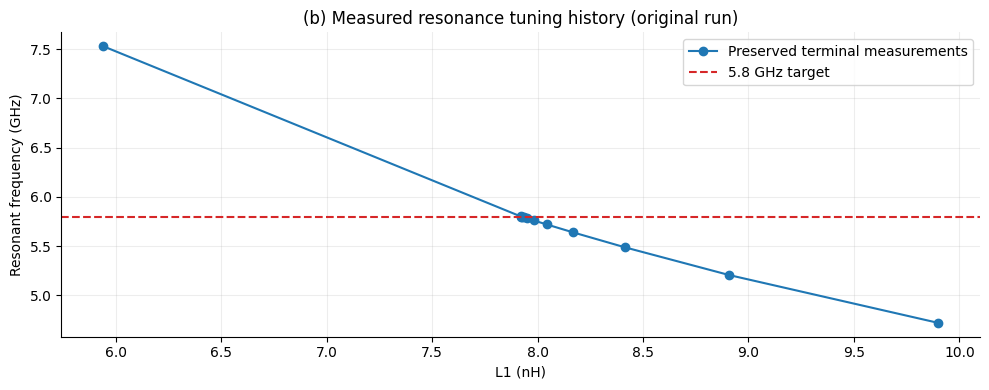

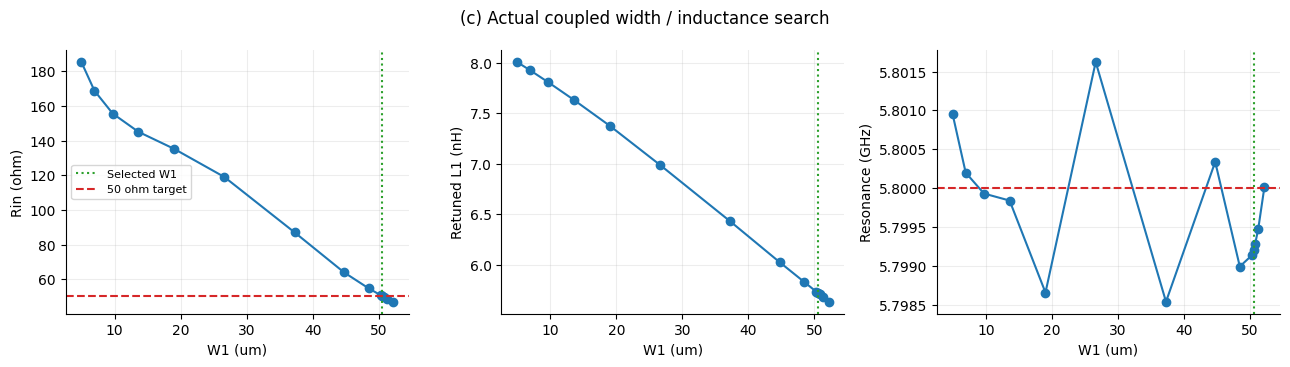

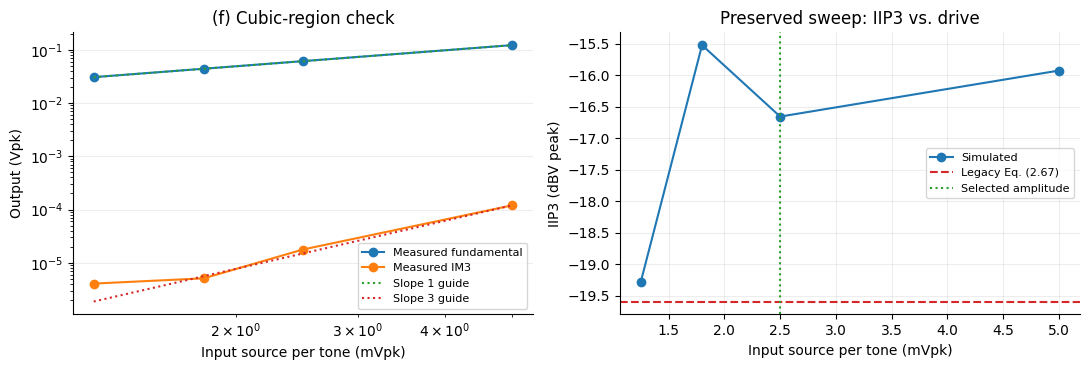

| Interval (mVpk) | Fund. slope | IM3 slope | Score |
|---|---|---|---|
| 2.5 - 5 | 0.998 | 2.755 | 0.247 |
| 1.8 - 2.5 | 0.999 | 3.794 | 0.795 |
| 1.25 - 1.8 | 1.000 | 0.624 | 2.377 |

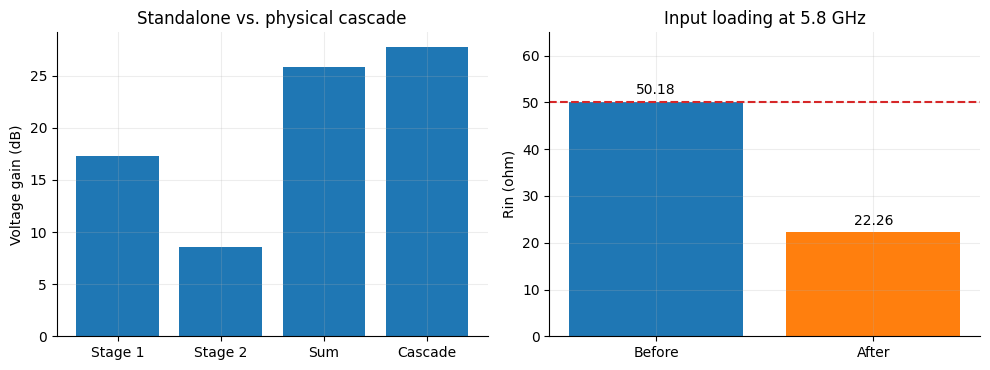

In [3]:
if EXECUTION_MODE == "review":
    show_summary()

## Two-tone FFT spectra (stem plots)
Compute input/output FFTs and transient plots from the received numerical traces in this local kernel.

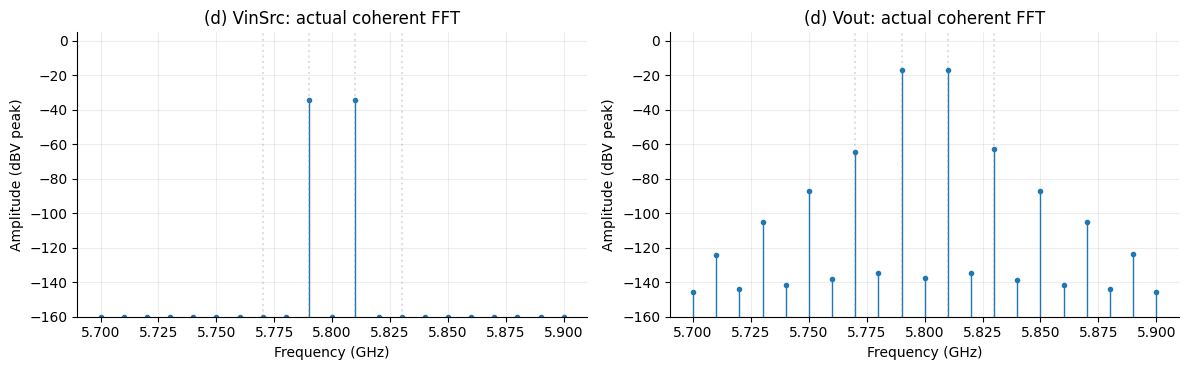

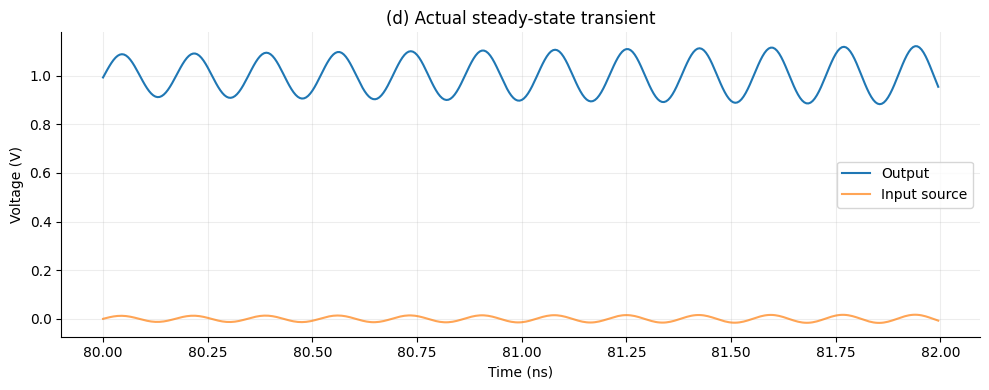

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -10.4916 |
| Exact coherent-window check | 20000 | -10.4927 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **-0.001 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

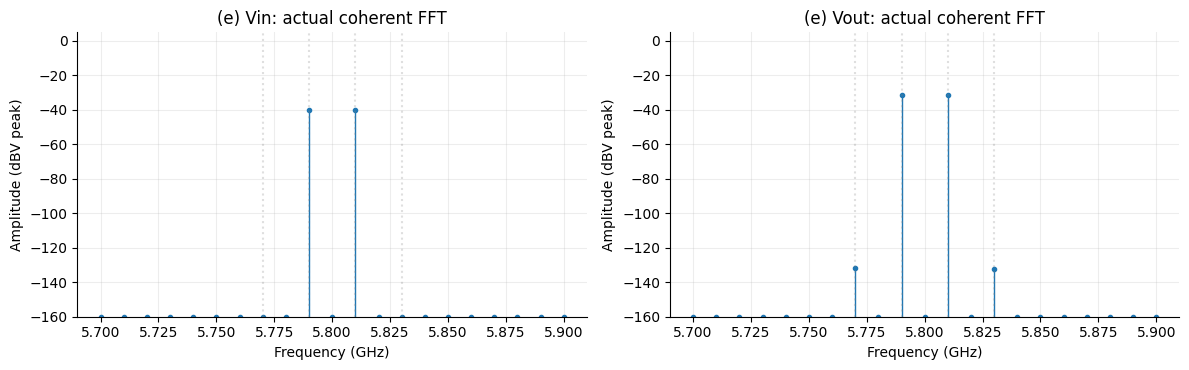

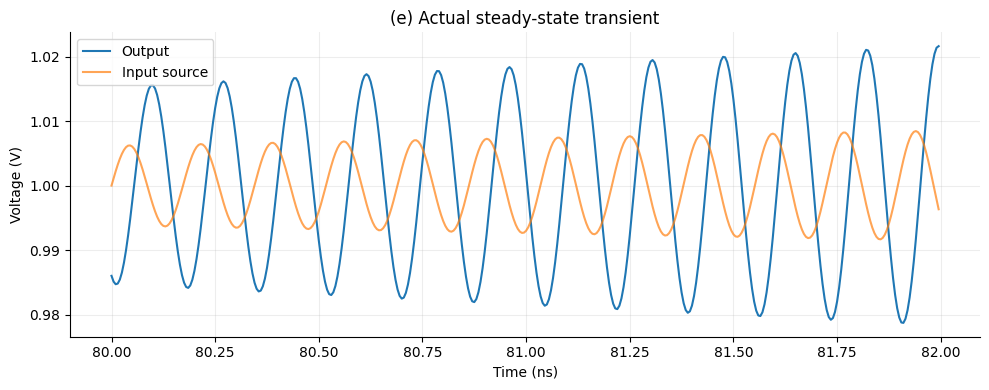

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -1.7533 |
| Exact coherent-window check | 20000 | 10.3137 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **+12.067 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

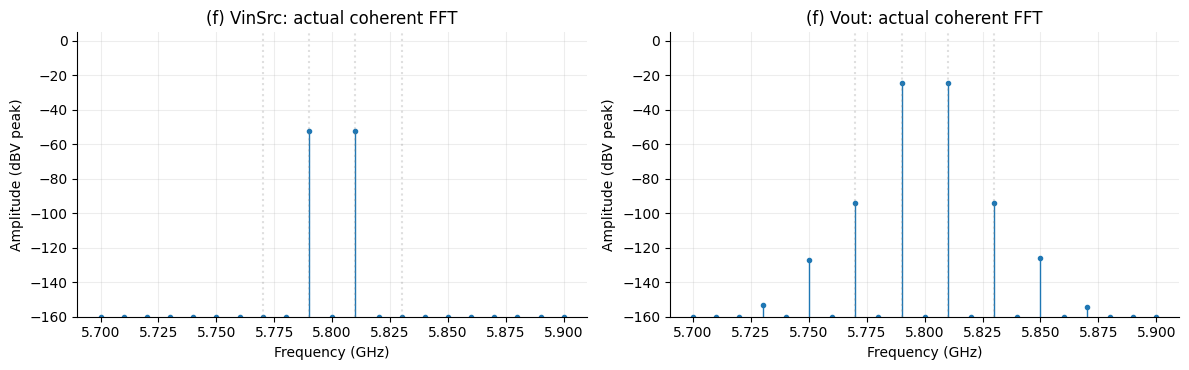

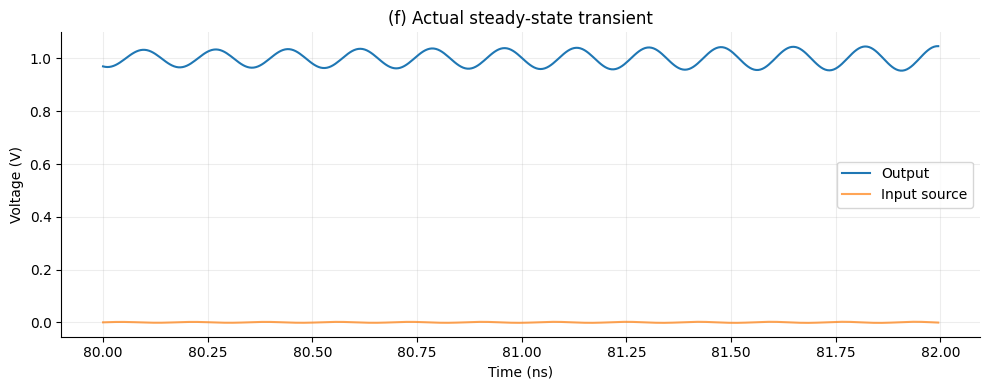

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -16.6554 |
| Exact coherent-window check | 20000 | -17.1918 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **-0.536 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

In [4]:
if EXECUTION_MODE == "review":
    for part in "def":
        spectrum(part, require_part(load_meta(), part)["outputs"])

## One-to-one workspace mapping

| Local | Remote |
|---|---|
| `Gatech-ECE6420/HW05/` | `/nethome/sjeon84/Gatech-ECE6420/HW05/` |
| `notebooks/`, `lib/`, `tools/`, `netlists/reference/` | Same relative paths; mirrored source |
| `results/curves/`, `netlists/generated/`, `simulation/` | Server numerical results and logs, fetched to the same paths |
| `results/figures/` | Rendered by the local kernel |

The default mode is `remote`. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without VPN. No Remote SSH extension or remote Jupyter connection is required.